In [12]:
import jax

print(jax.devices())

[CpuDevice(id=0)]


# The charging station

`pyspect` can set up problems independently from implementations...
At this stage, we only need to import pyspect and select a pyspect language...

In [13]:
import sys
import os

# Get the path to the parent folder of 'examples' (i.e., the 'pyscept' folder)
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add the 'src' directory to Python's search path
src_path = os.path.join(parent_dir, "src")
sys.path.append(src_path)

from math import pi
import numpy as np

from pyspect import *
from pyspect.langs.ltl import *
from pyspect.tlt import *
from pyspect.set_builder import *

TLT.select(ContinuousLTL)

## Environment

Let us first setup the 4-way intersection environment...

In [14]:
## CONSTANTS ##

# Define origin and size of area, makes it easier to scale up/down later on 
X0, XN = -2, 4
Y0, YN = -2, 4

dt = 0.2

STATE_INIT = [X0+7.5*XN/8, Y0+1.5*YN/8, np.pi, 0, 0]
print(STATE_INIT)

[1.75, -1.25, 3.141592653589793, 0, 0]


Speedlimit bound

In [15]:
## TRAFFIC RULES ##

parking_lot_speedlimit = BoundedSet(v=(0.0, 0.3))
high_way_speedlimit    = BoundedSet(v=(0.2, 0.5))

Setting up bounds

In [16]:
## ROADS ##

intersection = BoundedSet(x=(X0, X0 + 2/8*XN), y=(Y0 + 1.0/8*YN, Y0 + 3.0/8*YN))
# intersection = BoundedSet(x=(X0, X0 + 0.25*XN), y=(Y0 + 0.125*YN, Y0 + 0.375*YN))

road_n = BoundedSet(x=(X0 + 1.0/8*XN, X0 + 2/8*XN), h=(+pi/2 - pi/5, +pi/2 + pi/5))
# road_n = BoundedSet(x=(X0 + 0/8*XN, X0 + 3/8*XN))
road_n = Or(And(road_n, speedlimit), intersection)
# road_n = Or(road_n, intersection)

road_s = BoundedSet(x=(X0, X0 + 1.0/8*XN), h=(-pi/2 - pi/5, -pi/2 + pi/5))
road_s = Or(And(road_s, speedlimit), intersection)
# road_s = Or(road_s, intersection)

exit_n = And(BoundedSet(x=(X0 + 1.0/8*XN, X0 + 2.0/8*XN), y=(Y0 + 0.875*YN, Y0 + 1.000 * YN)), road_n)
exit_s = And(BoundedSet(x=(X0 + 0.0/8*XN, X0 + 1.0/8*XN), y=(Y0 + 0.000*YN, Y0 + 0.125 * YN)), road_s)

# entry_parking = BoundedSet(x=(X0 + 0.250*XN, X0 + 0.375*XN), y=(Y0 + 0.062*YN, Y0 + 0.250 * YN))
# exit_parking  = BoundedSet(x=(X0 + 0.250*XN, X0 + 0.375*XN), y=(Y0 + 0.250*YN, Y0 + 0.438 * YN))
entry_parking = BoundedSet(x=(X0 + 2/8*XN, X0 + 3/8*XN), y=(Y0 + 1/8*YN, Y0 + 2/8 * YN))
exit_parking  = BoundedSet(x=(X0 + 2/8*XN, X0 + 3/8*XN), y=(Y0 + 2/8*YN, Y0 + 3/8 * YN))

## PARKING LOT ##

parking_lot = Or(
    entry_parking,
    exit_parking,
    BoundedSet(x=(X0 + 3/8*XN, X0 + 1.0*XN), y=(Y0 + 0.0*YN, Y0 + 4/8*YN))   # Main box
)
parking_lot = And(parking_lot, speedlimit)

parking_space_1 = BoundedSet(x=(X0 + 0.875*XN, X0 + XN), y=(Y0, Y0 + 0.125*YN))
parking_space_2 = BoundedSet(x=(X0 + 0.875*XN, X0 + XN), y=(Y0 + 0.125*YN, Y0 + 0.25*YN))
parking_space_3 = BoundedSet(x=(X0 + 0.875*XN, X0 + XN), y=(Y0 + 0.25*YN, Y0 + 0.375*YN))

## Testing scenario

test_space = BoundedSet(x=(X0, X0 + XN), y=(Y0, Y0 + YN))
test_mid = BoundedSet(x=(X0+3*XN/8, X0+5*XN/8), y=(Y0+3*YN/8, Y0+5*YN/8))

In [17]:
def FollowTo(constraint, goal_or_constraint, *more):
    if more: # 2nd arg is constraint
        return FollowTo(And(constraint, goal_or_constraint), *more)
    else: # 2nd arg is exit
        return Until(constraint, goal_or_constraint)

Three vehicles in the scenario must follow these rules...

In [ ]:
vehicle_1 = FollowTo(Or(road_n, parking_lot), exit_n)

Implementation using `hj_reachability`.

In [19]:
import numpy as np
import hj_reachability as hj

class HJImpl(ContinuousLTL):

    solver_settings = hj.SolverSettings.with_accuracy("low")

    def __init__(self, dynamics, grid, time_horizon):
        self.grid = grid
        self.ndim = grid.ndim
        self.dynamics = dynamics
        self.timeline = self.new_timeline(time_horizon, time_step=dt)

    def new_timeline(self, target_time, start_time=0, time_step=0.2):
        assert time_step > 0
        is_forward = target_time >= start_time
        target_time += 1e-5 if is_forward else -1e-5
        time_step *= 1 if is_forward else -1
        return np.arange(start_time, target_time, time_step)

    def set_axes_names(self, *args):
        assert len(args) == self.ndim
        self._axes_names = tuple(args)

    def axis(self, name: str) -> int:
        assert name in self._axes_names, f'Axis ({name=}) does not exist.'
        return self._axes_names.index(name)

    def axis_name(self, i: int) -> str:
        assert i < len(self._axes_names), f'Axis ({i=}) does not exist.'
        return self._axes_names[i]

    def axis_is_periodic(self, i: int) -> bool:
        assert i < len(self._axes_names), f'Axis ({i=}) does not exist.'
        return bool(self.grid._is_periodic_dim[i])

    def plane_cut(self, normal, offset, axes=None):
        data = np.zeros(self.grid.shape)
        axes = axes or list(range(self.grid.ndim))
        x = lambda i: self.grid.states[..., i]
        for i, k, m in zip(axes, normal, offset):
            data -= k*x(i) - k*m
        return data

    def empty(self):
        return np.ones(self.grid.shape)*np.inf
    
    def complement(self, vf):
        return np.asarray(-vf)
    
    def intersect(self, vf1, vf2):
        return np.maximum(vf1, vf2)

    def union(self, vf1, vf2):
        return np.minimum(vf1, vf2)
    
    def reach(self, target, constraints=None):
        self.dynamics.with_mode('reach')
        if not self.is_invariant(target):
            target = np.flip(target, axis=0)
        if not self.is_invariant(constraints):
            constraints = np.flip(constraints, axis=0)
        vf = hj.solve(self.solver_settings,
                      self.dynamics,
                      self.grid,
                      -self.timeline,
                      target,
                      constraints)
        return np.flip(np.asarray(vf), axis=0)
    
    def avoid(self, target, constraints=None):
        self.dynamics.with_mode('avoid')
        if not self.is_invariant(target):
            target = np.flip(target, axis=0)
        if not self.is_invariant(constraints):
            constraints = np.flip(constraints, axis=0)
        vf = hj.solve(self.solver_settings,
                      self.dynamics,
                      self.grid,
                      -self.timeline,
                      target,
                      constraints)
        return np.flip(np.asarray(vf), axis=0)

    def project_onto(self, vf, *idxs, keepdims=False, union=True):
        idxs = [len(vf.shape) + i if i < 0 else i for i in idxs]
        dims = [i for i in range(len(vf.shape)) if i not in idxs]
        if union:
            return vf.min(axis=tuple(dims), keepdims=keepdims)
        else:
            return vf.max(axis=tuple(dims), keepdims=keepdims)

    def is_invariant(self, vf):
        return (True if vf is None else
                len(vf.shape) != len(self.timeline.shape + self.grid.shape))

    def make_tube(self, vf):
        return (vf if not self.is_invariant(vf) else
                np.concatenate([vf[np.newaxis, ...]] * len(self.timeline)))

In [ ]:
from hj_reachability.systems import Bicycle5D
from pyspect.plotting.levelsets import *

min_bounds_input = np.array([-np.pi, -0.2])
max_bounds_input = np.array([ np.pi,  0.2])
reach_dynamics = Bicycle5D(min_steer=min_bounds_input[0],
                           max_steer=max_bounds_input[0],
                           min_accel=min_bounds_input[1],
                           max_accel=max_bounds_input[1])

#                            x-pos  y-pos head   vel steering
min_bounds_state = np.array([   X0,    Y0, -pi, -0.7, -0.0])
max_bounds_state = np.array([XN+X0, YN+Y0, +pi, +0.7, +0.2])
grid = hj.Grid.from_lattice_parameters_and_boundary_conditions(hj.sets.Box(min_bounds_state, max_bounds_state),
                                                               (31, 31, 25, 11, 9),
                                                               periodic_dims=2)

t_max = 20

impl = HJImpl(reach_dynamics, grid, t_max)
impl.set_axes_names('x', 'y', 'h', 'd', 'v')


In [21]:

out1 = TLT.construct(vehicle_1).realize(impl)
# out2 = TLT.construct(vehicle_2).realize(impl)
# out3 = TLT.construct(vehicle_3).realize(impl)

Running for 100 iterations: 100%|██████████| 100/100 [37:11<00:00, 22.32s/it]


In [ ]:
plot3D_levelset(impl.project_onto(out1, 0, 1, 2, union=True),
                min_bounds=[0, *min_bounds_state[:2]],
                max_bounds=[t_max, *max_bounds_state[:2]])

In [ ]:
np.save("out1_isen.py", out1)

In [ ]:
### LOAD EXISTING FILE ###

import numpy as np
out1 = np.load("out1.npy")
print(out1.shape)

(76, 31, 31, 25, 7)


In [ ]:
### Useful tranform

def coord_to_index(coords):
    indices = []
    out1_shape = out1.shape
    for i in range(6):
        norm_value = (coords[i] - min_bounds_state[i]) / (max_bounds_state[i] - min_bounds_state[i])
        index = round(norm_value * (out1_shape[i] - 1))
        index = max(0, min(index, out1_shape[i] - 1))
        indices.append(index)

    return tuple(indices)

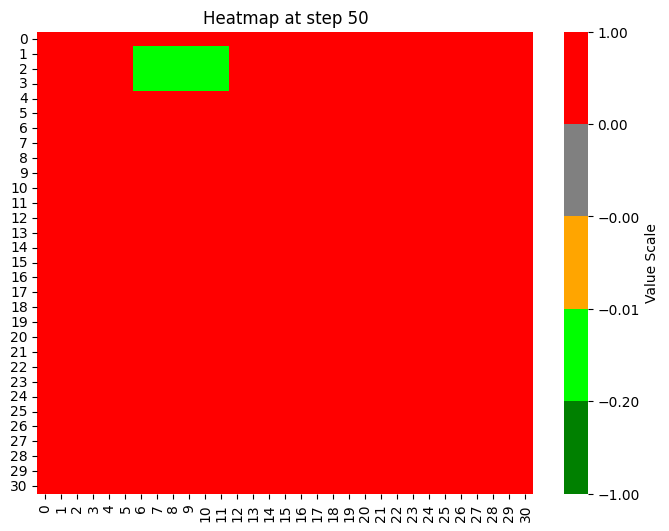

In [89]:
### HEAT-MAP ###

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns

# Example: Create a matrix of arrays

t = 50
# out1_heat_pos = np.rot90(out1[t,:,:,:,:,1].min(axis=(2,3)))
out1_heat_pos = np.rot90(out1[t].min(axis=(2,3,4)))


# Create a custom colormap where 0 is gray and other values use coolwarm
colors = ["green","lime", "orange", "gray", "red"]  # Include gray for 0
cmap = ListedColormap(colors)

# Define boundaries to control the color mapping
bounds = [-1,-0.2,-0.01, -1e-5, 0, 1]  # Ensure 0 is within its own boundary
norm = BoundaryNorm(bounds, cmap.N)

# Plot the heatmap
plt.figure(figsize=(8, 6))
heatmap = sns.heatmap(out1_heat_pos, cmap=cmap, norm=norm, cbar_kws={'ticks': bounds, 'label': 'Value Scale'})

plt.title("Heatmap at step "+str(t))
plt.show()

(31, 31) (31, 31)
-1.8666668


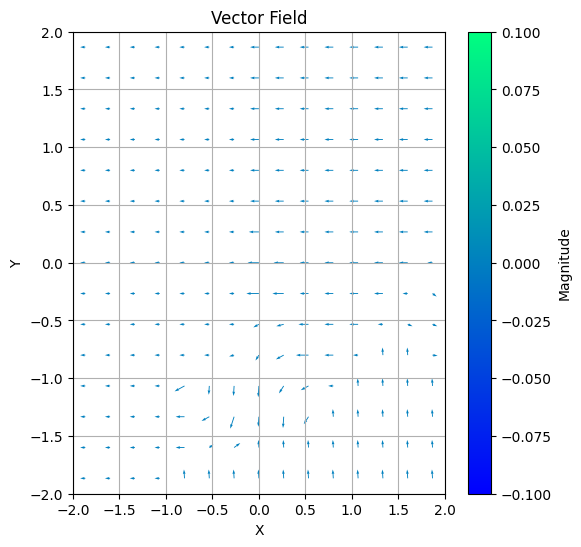

In [17]:
### VECTOR FIELD (whole area) ###

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns


# Create a custom colormap where 0 is gray and other values use coolwarm
colors = ["lime", "gray", "red"]  # Include gray for 0
cmap = ListedColormap(colors)

# Define boundaries to control the color mapping
bounds = [-1,-1e-5, 0, 1]  # Ensure 0 is within its own boundary
norm = BoundaryNorm(bounds, cmap.N)


# Define grid
x, y = np.meshgrid(np.linspace(X0, X0+XN, 31), np.linspace(Y0, Y0+YN, 31))
print(np.shape(x),np.shape(y))

u = np.zeros(np.shape(x))
v = np.zeros(np.shape(y))

value_array = np.zeros(np.shape(x))

t = 0


for row in range(len(out1[t,0,:,0,0])):
    for col in range(len(out1[t,:,0,0,0])):
        
        min_value = np.min(out1[0,col,row,:,:])
        min_index = np.where(out1[0,col,row,:,:] == min_value)
        if np.shape(min_index) != (2, 1):
            ind_theta = min_index[0][0]
            ind_v = min_index[1][0]
            
        else:
            ind_theta, ind_v = min_index

        u[col,row] = (0.3 + 0.5*ind_v/7) * np.cos((-1 + 2*ind_theta/25) * np.pi)
        v[col,row] = (0.3 + 0.5*ind_v/7) * np.sin((-1 + 2*ind_theta/25) * np.pi)

        # value_array[col,row] = -1 * len(min_index[0])
        # print(len(min_index[0]))
        value_array[col,row] = min(value_array[col,row],1e-5)
        # print(u[col,row],v[col,row])

print(np.min(out1[t]))
# print(out1[t,:,:,:,:])
# Plot vector field
plt.figure(figsize=(6,6))
plt.quiver(x, y, u, v, value_array, cmap="winter")

# Show plot
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Vector Field")
plt.colorbar(label="Magnitude")
plt.xlim([-2,2])
plt.ylim([-2,2])
plt.grid()
plt.show()
